<a href="https://colab.research.google.com/github/DEESHA-AFK/MACHINE-LEARNING-FUNDAMENTALS/blob/main/T076_ML_PRAC_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

AIM: KNN for handwritten digit recognition
Apply KNN on sklearn digits dataset (real-world banking/postal OCR systems).
Visualize nearest neighbors for 3 test images.

Load Dataset & Before KNN Graph

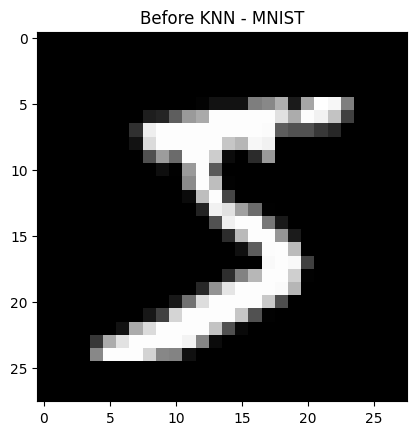

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

mnist = fetch_openml('mnist_784', version=1, as_frame=False)

X = mnist.data[:10000] / 255.0
y = mnist.target[:10000].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

plt.imshow(X[0].reshape(28,28), cmap='gray')
plt.title("Before KNN - MNIST")
plt.show()

Apply KNN & Find Nearest Neighbours

In [3]:
model = KNeighborsClassifier(n_neighbors=3, n_jobs=-1)
model.fit(X_train, y_train)

pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, pred)*100, "%")

for i in range(3):
    distances, indices = model.kneighbors([X_test[i]])
    print("Actual:", y_test[i], "Predicted:", pred[i])
    print("Neighbours:", y_train[indices[0]])

Accuracy: 97.12857142857143 %
Actual: 8 Predicted: 8
Neighbours: [8 8 8]
Actual: 4 Predicted: 4
Neighbours: [4 4 4]
Actual: 8 Predicted: 8
Neighbours: [8 8 8]


After KNN & Visualize 3 Test Images

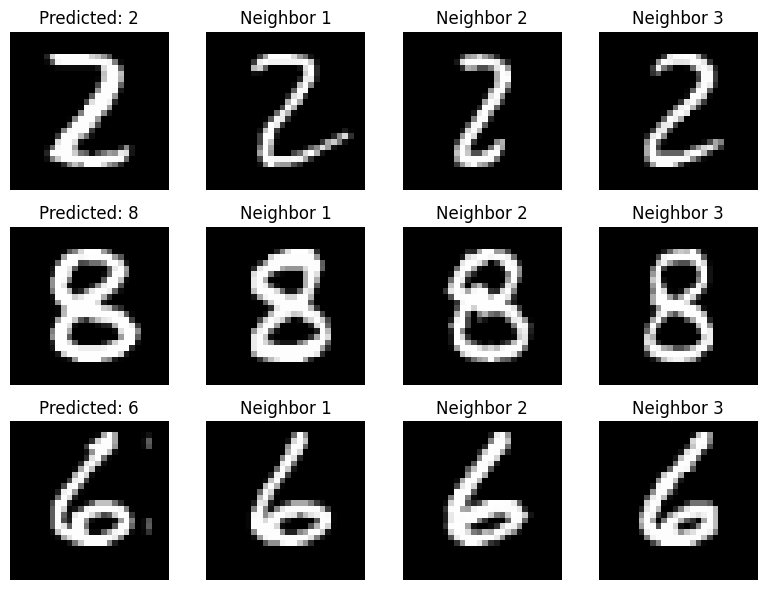

In [7]:
# Re-train the model to ensure the indices map correctly to X_train (size 8000)
model = KNeighborsClassifier(n_neighbors=3, n_jobs=-1)
model.fit(X_train, y_train)
pred = model.predict(X_test)

fig, ax = plt.subplots(3, 4, figsize=(8,6))

for i in range(3):
    # Get neighbors from the newly fitted model
    distances, indices = model.kneighbors(X_test[i:i+1])

    # Display the test image
    ax[i,0].imshow(X_test[i].reshape(28,28), cmap='gray')
    ax[i,0].set_title("Predicted: " + str(pred[i]))

    # Display its 3 nearest neighbors
    for j in range(3):
        neighbor_idx = indices[0][j]
        ax[i,j+1].imshow(X_train[neighbor_idx].reshape(28,28), cmap='gray')
        ax[i,j+1].set_title("Neighbor " + str(j+1))

    for a in ax[i]:
        a.axis('off')

plt.tight_layout()
plt.show()